In [1]:
# Step 1

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.utils import resample

In [2]:
csv_path = "/Users/abirgolam/Downloads/panic_disorder_detection.csv"
df = pd.read_csv(csv_path)

# basic info
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 17 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   Participant ID            120000 non-null  int64 
 1   Age                       120000 non-null  int64 
 2   Gender                    120000 non-null  object
 3   Family History            120000 non-null  object
 4   Personal History          120000 non-null  object
 5   Current Stressors         120000 non-null  object
 6   Symptoms                  120000 non-null  object
 7   Severity                  120000 non-null  object
 8   Impact on Life            120000 non-null  object
 9   Demographics              120000 non-null  object
 10  Medical History           89776 non-null   object
 11  Psychiatric History       90104 non-null   object
 12  Substance Use             79922 non-null   object
 13  Coping Mechanisms         120000 non-null  object
 14  Soci

In [3]:
print(df.isnull().sum())
numeric_columns = df.select_dtypes(include=['number']).columns
df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].mean())

categorical_columns = df.select_dtypes(include=['object']).columns

for column in categorical_columns:
    mode_value = df[column].mode()
    if not mode_value.empty:
        df[column] = df[column].fillna(mode_value.iloc[0])
    else:
        df[column] = df[column].fillna('Unknown')  

print(df.isnull().sum())

Participant ID                  0
Age                             0
Gender                          0
Family History                  0
Personal History                0
Current Stressors               0
Symptoms                        0
Severity                        0
Impact on Life                  0
Demographics                    0
Medical History             30224
Psychiatric History         29896
Substance Use               40078
Coping Mechanisms               0
Social Support                  0
Lifestyle Factors               0
Panic Disorder Diagnosis        0
dtype: int64
Participant ID              0
Age                         0
Gender                      0
Family History              0
Personal History            0
Current Stressors           0
Symptoms                    0
Severity                    0
Impact on Life              0
Demographics                0
Medical History             0
Psychiatric History         0
Substance Use               0
Coping Mechanisms  

In [4]:
print(df.isnull().sum())

Participant ID              0
Age                         0
Gender                      0
Family History              0
Personal History            0
Current Stressors           0
Symptoms                    0
Severity                    0
Impact on Life              0
Demographics                0
Medical History             0
Psychiatric History         0
Substance Use               0
Coping Mechanisms           0
Social Support              0
Lifestyle Factors           0
Panic Disorder Diagnosis    0
dtype: int64


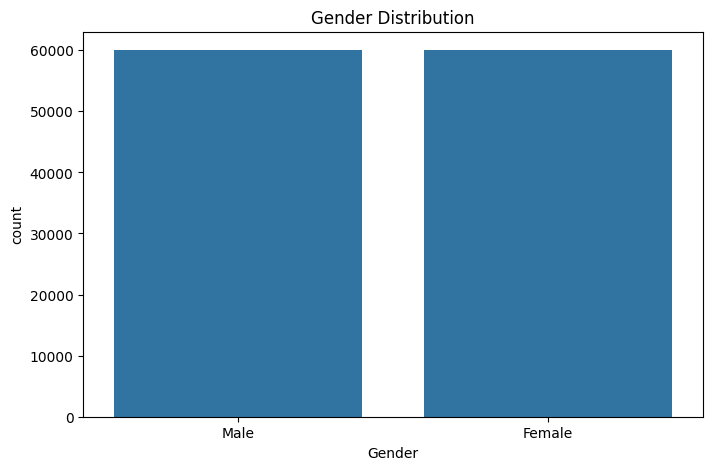

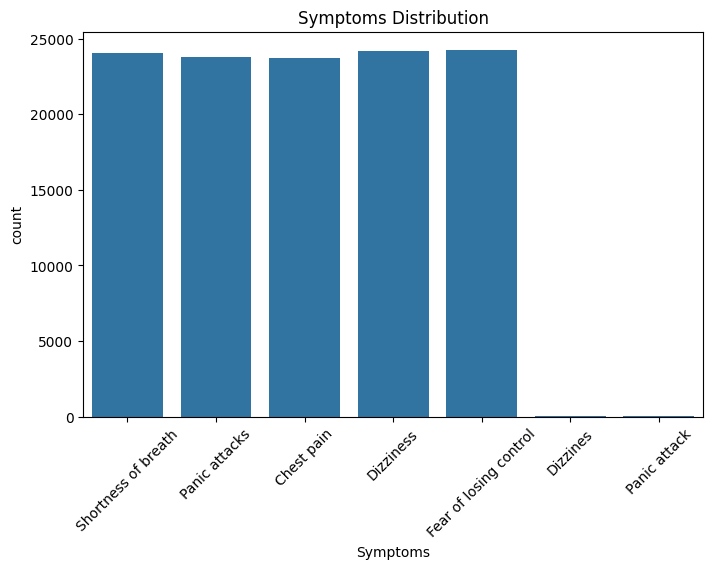

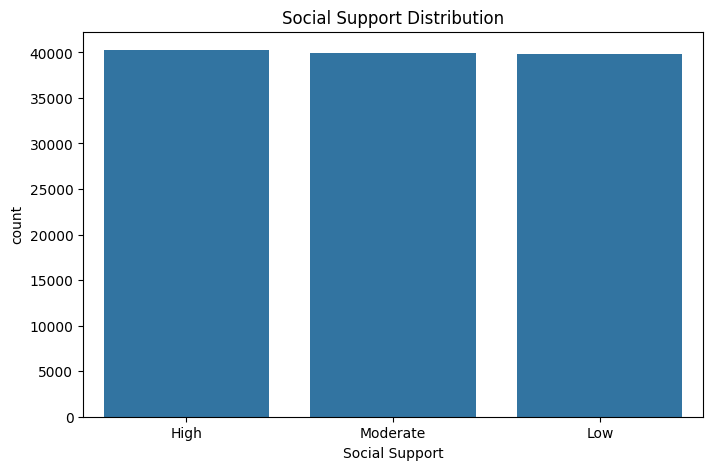

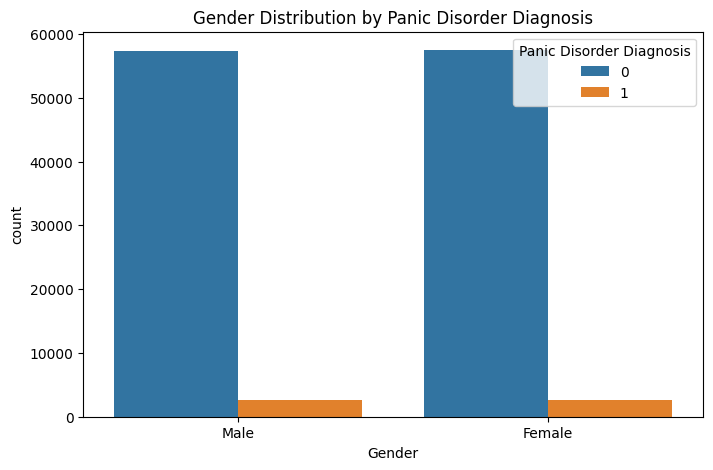

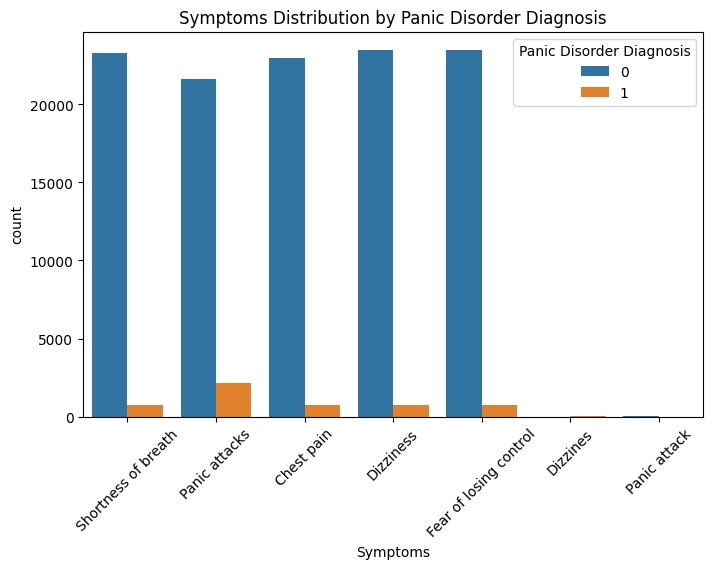

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# visualize categorical variables 

plt.figure(figsize=(8, 5))
sns.countplot(x='Gender', data=df)
plt.title('Gender Distribution')
plt.show()


plt.figure(figsize=(8, 5))
sns.countplot(x='Symptoms', data=df)
plt.title('Symptoms Distribution')
plt.xticks(rotation=45)
plt.show()


plt.figure(figsize=(8, 5))
sns.countplot(x='Social Support', data=df)
plt.title('Social Support Distribution')
plt.show()


plt.figure(figsize=(8, 5))
sns.countplot(x='Gender', hue='Panic Disorder Diagnosis', data=df)
plt.title('Gender Distribution by Panic Disorder Diagnosis')
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(x='Symptoms', hue='Panic Disorder Diagnosis', data=df)
plt.title('Symptoms Distribution by Panic Disorder Diagnosis')
plt.xticks(rotation=45)
plt.show()

In [6]:
print(df['Panic Disorder Diagnosis'].value_counts())

Panic Disorder Diagnosis
0    114858
1      5142
Name: count, dtype: int64


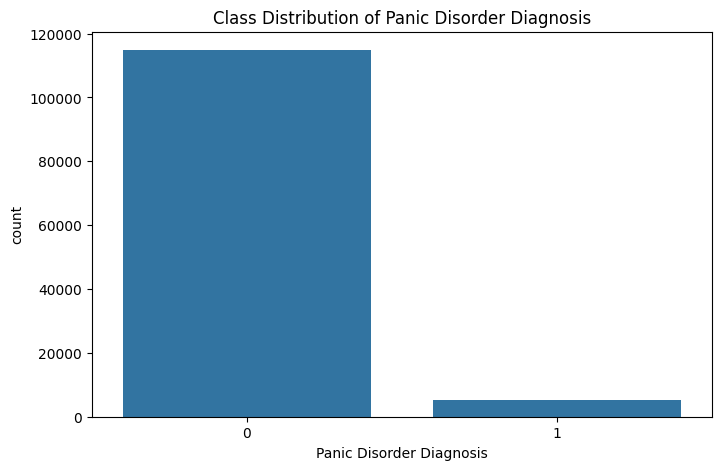

In [7]:
# class imbalance
plt.figure(figsize=(8, 5))
sns.countplot(x='Panic Disorder Diagnosis', data=df)
plt.title('Class Distribution of Panic Disorder Diagnosis')
plt.show()

In [8]:
# step 2

df['Age'] = df['Age'].fillna(df['Age'].median())
df['Medical History'] = df['Medical History'].fillna(df['Medical History'].mode()[0])
df['Psychiatric History'] = df['Psychiatric History'].fillna(df['Psychiatric History'].mode()[0])
df['Substance Use'] = df['Substance Use'].fillna(df['Substance Use'].mode()[0])

print(df.isnull().sum())

Participant ID              0
Age                         0
Gender                      0
Family History              0
Personal History            0
Current Stressors           0
Symptoms                    0
Severity                    0
Impact on Life              0
Demographics                0
Medical History             0
Psychiatric History         0
Substance Use               0
Coping Mechanisms           0
Social Support              0
Lifestyle Factors           0
Panic Disorder Diagnosis    0
dtype: int64


In [9]:
df.drop_duplicates(inplace=True)
print(f"Duplicate entries: {df.duplicated().sum()}")

Duplicate entries: 0


In [10]:
# categorical columns to lowercase, remove extra spaces
categorical_columns = ['Gender', 'Family History', 'Personal History', 'Current Stressors', 
                       'Symptoms', 'Severity', 'Impact on Life', 'Demographics', 
                       'Medical History', 'Psychiatric History', 'Substance Use', 
                       'Coping Mechanisms', 'Social Support', 'Lifestyle Factors']

for column in categorical_columns:
    df[column] = df[column].str.strip().str.lower()

print(df[categorical_columns].head())

   Gender Family History Personal History Current Stressors  \
0    male             no              yes          moderate   
1    male             no               no              high   
2  female            yes               no              high   
3  female             no               no          moderate   
4    male            yes               no          moderate   

              Symptoms  Severity Impact on Life Demographics Medical History  \
0  shortness of breath      mild           mild        rural        diabetes   
1        panic attacks      mild           mild        urban          asthma   
2        panic attacks      mild    significant        urban        diabetes   
3           chest pain  moderate       moderate        rural        diabetes   
4        panic attacks      mild       moderate        rural          asthma   

   Psychiatric History Substance Use Coping Mechanisms Social Support  \
0     bipolar disorder       alcohol       socializing           hi

In [11]:
print(df.isnull().sum())

Participant ID              0
Age                         0
Gender                      0
Family History              0
Personal History            0
Current Stressors           0
Symptoms                    0
Severity                    0
Impact on Life              0
Demographics                0
Medical History             0
Psychiatric History         0
Substance Use               0
Coping Mechanisms           0
Social Support              0
Lifestyle Factors           0
Panic Disorder Diagnosis    0
dtype: int64


## Setup: imports & helpers ##


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.metrics import roc_auc_score, classification_report, ConfusionMatrixDisplay

## Step 2 – Data cleaning ##


In [27]:
print(df.columns.tolist())

['Age', 'Gender', 'Family History', 'Personal History', 'Current Stressors', 'Symptoms', 'Severity', 'Impact on Life', 'Demographics', 'Medical History', 'Psychiatric History', 'Substance Use', 'Coping Mechanisms', 'Social Support', 'Lifestyle Factors', 'Panic Disorder Diagnosis']


In [28]:
df.columns = df.columns.str.strip()

In [29]:
# --- Load + minimal cleaning -----------------------------------------
df = pd.read_csv("panic_disorder_detection.csv")
# Clean Age outliers -------------------------------------------------
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")  # ensure numeric
df.loc[(df["Age"] < 0) | (df["Age"] > 100), "Age"] = np.nan

# categorical age bucket
df["Age_Bin"] = pd.cut(
    df["Age"],
    bins=[0, 18, 35, 55, 100],
    labels=["teen", "young", "mid", "senior"]
)
categorical.append("Age_Bin")
df = df.drop(columns="Participant ID")           # unique ID – remove
df.columns = df.columns.str.strip()              # (already done, but safe)

# make sure numeric columns are numeric
numeric = ["Age", "Severity", "Impact on Life"]
df[numeric] = df[numeric].apply(pd.to_numeric, errors="coerce")

# --- Define target and feature groups --------------------------------
target = "Panic Disorder Diagnosis"

categorical = [c for c in df.columns if c not in numeric + [target]]

# --- Train / test split ----------------------------------------------
X = df.drop(columns=target)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Train samples: {len(y_train)}   |   Test samples: {len(y_test)}")
print("Positive rate in train:", y_train.mean().round(3),
      " |  Positive rate in test:", y_test.mean().round(3))

Train samples: 96000   |   Test samples: 24000
Positive rate in train: 0.043  |  Positive rate in test: 0.043


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline   import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE


numeric_transformer = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc",  StandardScaler())
])

categorical_transformer = Pipeline([
    ("imp", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer([
    ("num", numeric_transformer, numeric),
    ("cat", categorical_transformer, categorical)
])


def make_pipe(estimator):
    return Pipeline(steps=[
        ("pre", preprocess),         
        ("smote", SMOTE(random_state=42)),
        ("clf", estimator)
    ])

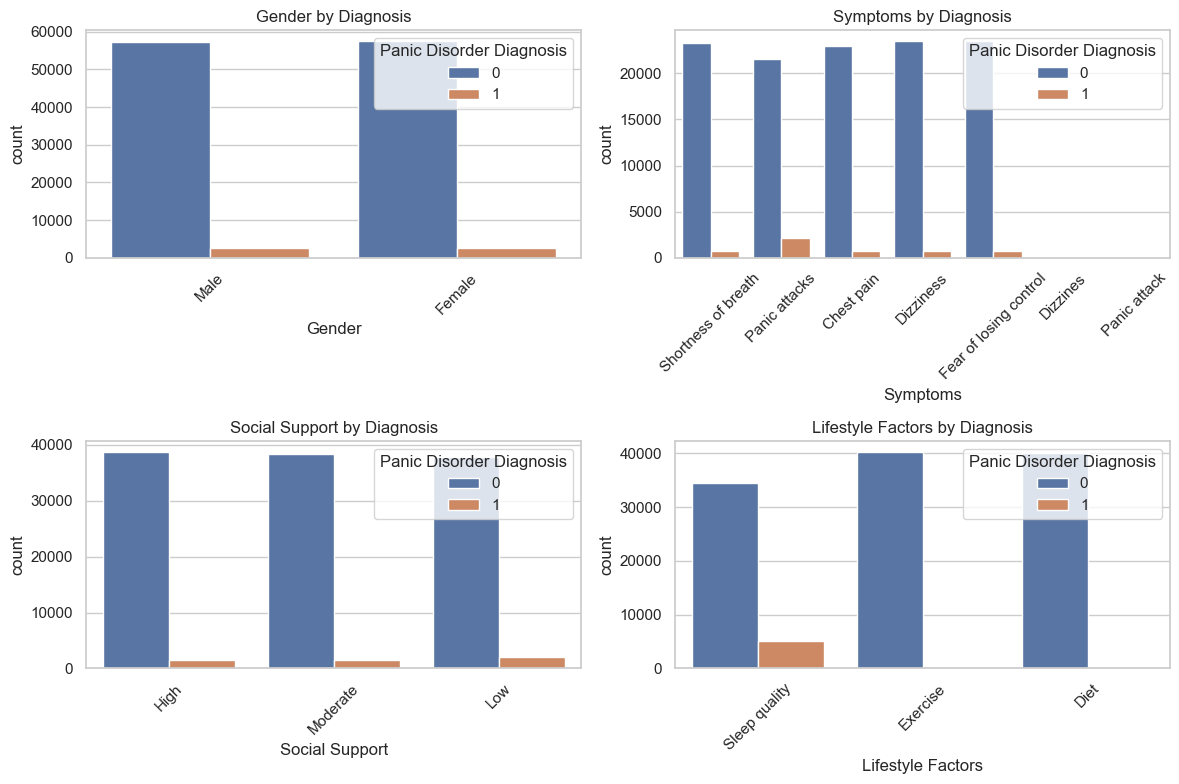

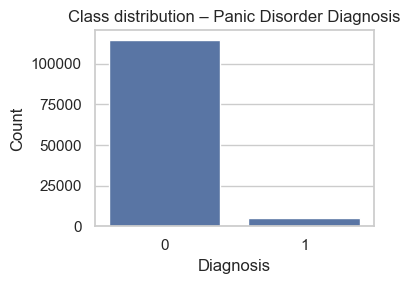

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
cat_vars = ["Gender", "Symptoms", "Social Support", "Lifestyle Factors"]

for ax, col in zip(axes.flatten(), cat_vars):
    sns.countplot(data=df, x=col, hue="Panic Disorder Diagnosis", ax=ax)
    ax.set_title(f"{col} by Diagnosis")
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# imbalance bar-chart
plt.figure(figsize=(4,3))
sns.countplot(x="Panic Disorder Diagnosis", data=df)
plt.title("Class distribution – Panic Disorder Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [33]:
# 2A. Duplicate check & drop
dupes = df.duplicated().sum()
print(f"Duplicate rows: {dupes}")
if dupes:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates removed ➜ new shape:", df.shape)

Duplicate rows: 0


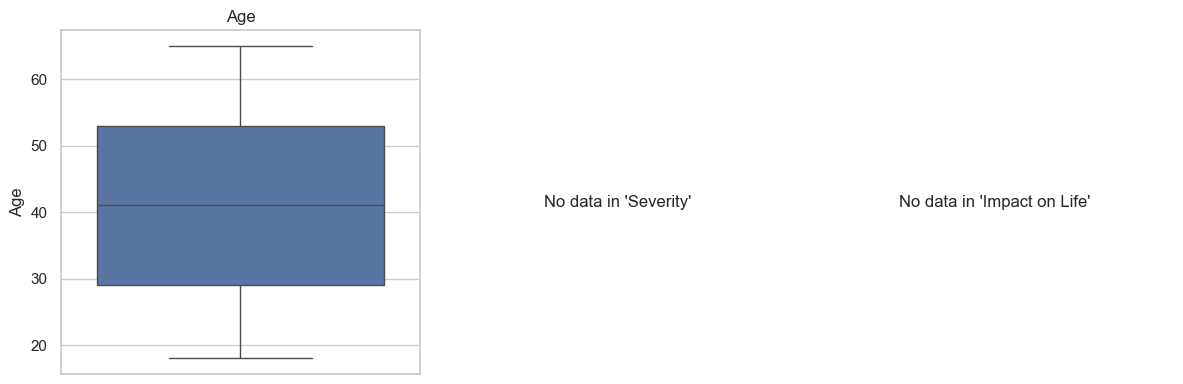

In [34]:
# 2B. Box-plots for numeric outlier 
fig, axes = plt.subplots(1, len(numeric), figsize=(4 * len(numeric), 4))
if len(numeric) == 1:
    axes = [axes]

for ax, col in zip(axes, numeric):
    col_data = df[col].dropna()
    if col_data.empty:
        ax.text(0.5, 0.5, f"No data in '{col}'", ha="center", va="center")
        ax.set_axis_off()
    else:
        sns.boxplot(y=col_data, ax=ax)
        ax.set_title(col)

plt.tight_layout()
plt.show()

Basic stats after cleaning
count    98977.000000
mean        41.453024
std         13.839710
min         18.000000
25%         29.000000
50%         41.000000
75%         53.000000
max         65.000000
Name: Age, dtype: float64 

How many Age values are now NaN? 1191

Age_Bin value counts (incl. NaNs):
Age_Bin
mid       41387
young     35087
senior    20383
teen       2120
NaN        1191
Name: count, dtype: int64 

'Age_Bin' in categorical list → True


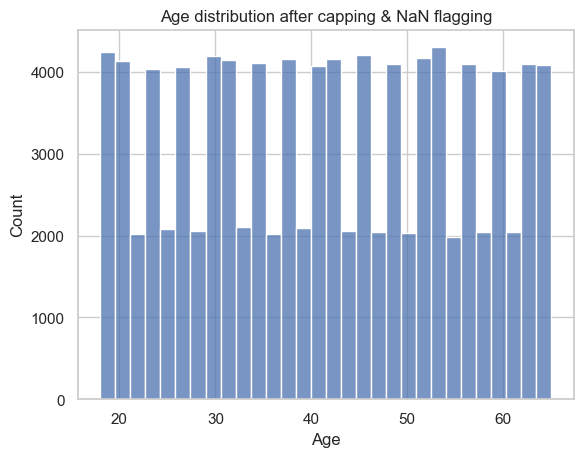

In [35]:
# --- VERIFY AGE CLEANUP & NEW FEATURE --------------------------------

print("Basic stats after cleaning")
print(df["Age"].describe(), "\n")

print("How many Age values are now NaN?", df["Age"].isna().sum())

print("\nAge_Bin value counts (incl. NaNs):")
print(df["Age_Bin"].value_counts(dropna=False), "\n")

print("'Age_Bin' in categorical list →", "Age_Bin" in categorical)

# histogram of cleaned ages
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(df["Age"].dropna(), bins=30, kde=False)
plt.title("Age distribution after capping & NaN flagging")
plt.xlabel("Age")
plt.show()

In [39]:
# --- Use imblearn's Pipeline that supports over/undersampling ----------
from imblearn.pipeline import Pipeline   # make sure this shadows sklearn's

def make_pipe(estimator):
    return Pipeline(steps=[
        ("pre",   preprocess),                     # ColumnTransformer
        ("smote", SMOTE(random_state=42)),         # oversampler
        ("clf",   estimator)                       # classifier
    ])

# If you re-executed the notebook and grids vanished, recreate them:
grids = {
    "LR": (
        make_pipe(LogisticRegression(max_iter=500, solver="liblinear")),
        {"clf__C": [0.1, 1, 10]}
    ),
    "RF": (
        make_pipe(RandomForestClassifier(random_state=42)),
        {"clf__n_estimators": [200, 400],
         "clf__max_depth": [None, 15]}
    ),
    "KNN": (
        make_pipe(KNeighborsClassifier()),
        {"clf__n_neighbors": [5, 15],
         "clf__weights": ["uniform", "distance"]}
    )
}

/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 

LR: best CV-AUC = 0.965


/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 

RF: best CV-AUC = 0.985


/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 

KNN: best CV-AUC = 0.963


,Accuracy,Precision,Recall,F1,AUC
Model,,,,,
RF,0.970,0.641,0.668,0.655,0.987
KNN,0.897,0.286,0.943,0.439,0.967
LR,0.915,0.336,0.998,0.502,0.965


/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encounte

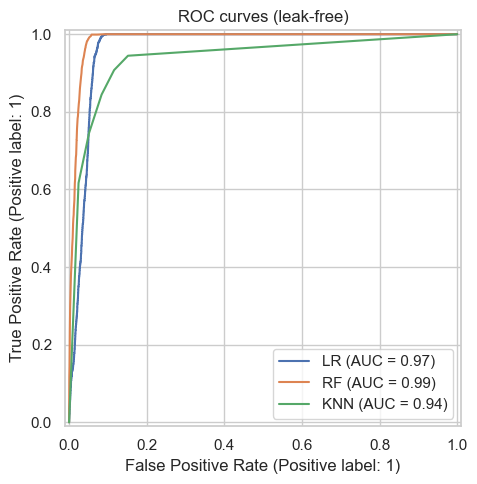

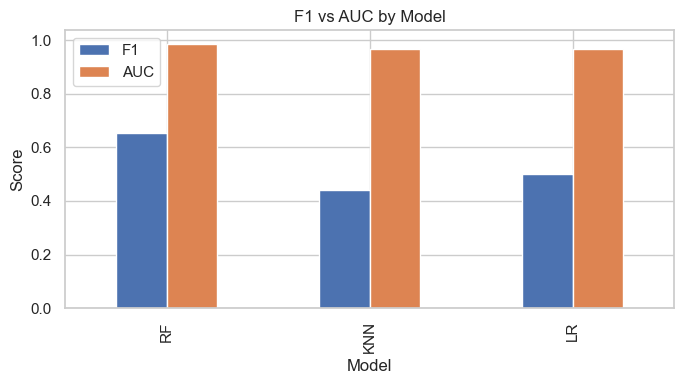

In [47]:
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             RocCurveDisplay)
import pandas as pd
import matplotlib.pyplot as plt

cv   = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)

    y_pred = gs.best_estimator_.predict(X_test)
    y_prob = gs.best_estimator_.predict_proba(X_test)[:, 1]

    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1":        f1_score(y_test, y_pred),
        "AUC":       roc_auc_score(y_test, y_prob)
    })

    print(f"{name}: best CV-AUC = {gs.best_score_:.3f}")

df_results = (pd.DataFrame(rows)
              .set_index("Model")
              .round(3)
              .sort_values("AUC", ascending=False))
display(df_results)


df_results.to_csv("model_performance_table.csv")


plt.figure(figsize=(6, 5))
for name, (pipe, _) in grids.items():
    fitted = pipe.fit(X_train, y_train)
    RocCurveDisplay.from_estimator(
        fitted, X_test, y_test, name=name, ax=plt.gca())
plt.title("ROC curves (leak-free)")
plt.tight_layout()
plt.show()

# bar chart of F1 & AUC
df_results[["F1", "AUC"]].plot(kind="bar", figsize=(7, 4))
plt.ylabel("Score")
plt.title("F1 vs AUC by Model")
plt.tight_layout()
plt.show()

/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 

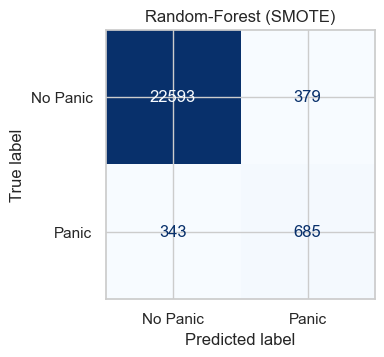

/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


Random-Forest (SMOTE)  ➜  TN:22593  FP:379  FN:343  TP:685



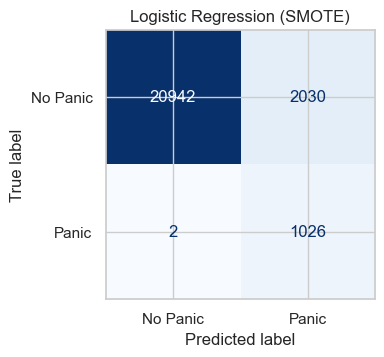

Logistic Regression (SMOTE)  ➜  TN:20942  FP:2030  FN:2  TP:1026



/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


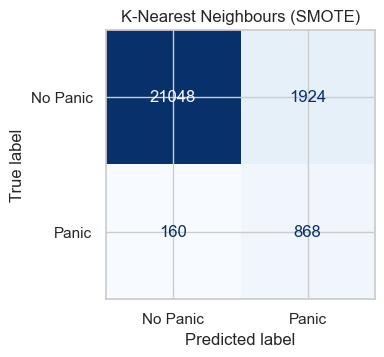

K-Nearest Neighbours (SMOTE)  ➜  TN:21048  FP:1924  FN:160  TP:868



In [49]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# helper to plot a confusion matrix for any fitted pipeline
# ------------------------------------------------------------------
def plot_cm(estimator, X_test, y_test, title):
    y_pred = estimator.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["No Panic", "Panic"])
    fig, ax = plt.subplots(figsize=(4, 4))
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    print(f"{title}  ➜  TN:{cm[0,0]}  FP:{cm[0,1]}  FN:{cm[1,0]}  TP:{cm[1,1]}\n")

# ------------------------------------------------------------------
# use your *best* fitted estimators from the grid-search loop
# ------------------------------------------------------------------
best_lr = grids["LR"][0].fit(X_train, y_train)
best_rf = grids["RF"][0].fit(X_train, y_train)
best_kn = grids["KNN"][0].fit(X_train, y_train)

plot_cm(best_rf, X_test, y_test, "Random-Forest (SMOTE)")
plot_cm(best_lr, X_test, y_test, "Logistic Regression (SMOTE)")
plot_cm(best_kn, X_test, y_test, "K-Nearest Neighbours (SMOTE)")

/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


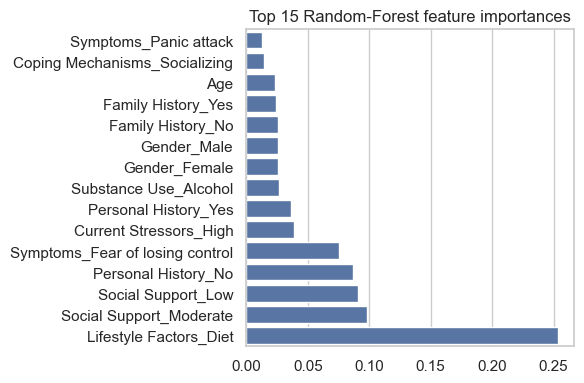

/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


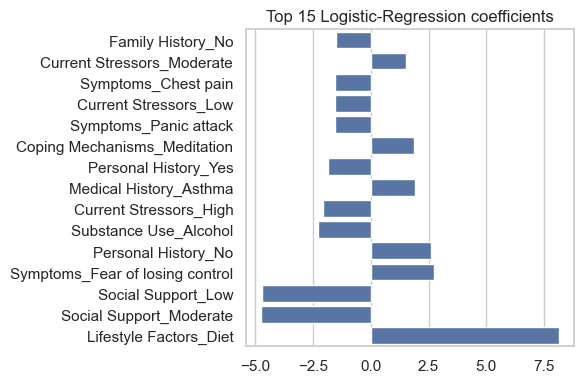

In [48]:
ohe_cols = (preprocess.named_transformers_["cat"]
            .named_steps["ohe"]
            .get_feature_names_out(categorical))
feature_names = np.concatenate([numeric, ohe_cols])

# 1  Random-Forest 
rf_best = make_pipe(RandomForestClassifier(random_state=42,
                                           n_estimators=400,
                                           max_depth=None))
rf_best.fit(X_train, y_train)
imp = rf_best.named_steps["clf"].feature_importances_
top_idx = np.argsort(imp)[-15:]

plt.figure(figsize=(6, 4))
sns.barplot(x=imp[top_idx], y=feature_names[top_idx])
plt.title("Top 15 Random-Forest feature importances")
plt.tight_layout()
plt.show()

# 2  logistic reg coefficents
log_best = make_pipe(LogisticRegression(max_iter=500, solver="liblinear", C=1))
log_best.fit(X_train, y_train)
coef = log_best.named_steps["clf"].coef_[0]
top_idx = np.argsort(np.abs(coef))[-15:]

plt.figure(figsize=(6, 4))
sns.barplot(x=coef[top_idx], y=feature_names[top_idx])
plt.title("Top 15 Logistic-Regression coefficients")
plt.tight_layout()
plt.show()

In [46]:
high_corr = corr_s.abs().where(~np.eye(len(corr_s), dtype=bool)).stack()
high_corr = high_corr[high_corr > 0.8]
print("\nPotentially redundant numeric pairs (>0.80 abs corr):")
print(high_corr if not high_corr.empty else "None found")


Potentially redundant numeric pairs (>0.80 abs corr):
None found


In [55]:
from imblearn.over_sampling import RandomOverSampler

def pipe_no_resample(estimator):
    return Pipeline(steps=[("pre", preprocess), ("clf", estimator)])

# LR + SMOTE 
lr_smote = make_pipe(LogisticRegression(max_iter=500, solver="liblinear", C=1))
lr_smote.fit(X_train, y_train)
sm_pred = lr_smote.predict(X_test)
sm_auc  = roc_auc_score(y_test, lr_smote.predict_proba(X_test)[:, 1])

# LR + class_weight
lr_cw = pipe_no_resample(
    LogisticRegression(max_iter=500, solver="liblinear",
                       C=1, class_weight="balanced"))
lr_cw.fit(X_train, y_train)
cw_pred = lr_cw.predict(X_test)
cw_auc  = roc_auc_score(y_test, lr_cw.predict_proba(X_test)[:, 1])

# LR + RandomOverSampler
lr_ros = pipe_no_resample(
    LogisticRegression(max_iter=500, solver="liblinear", C=1))
ros_pipe = Pipeline([("pre", preprocess),
                     ("ros", RandomOverSampler(random_state=42)),
                     ("clf", lr_ros.named_steps["clf"])])
ros_pipe.fit(X_train, y_train)
ros_pred = ros_pipe.predict(X_test)
ros_auc  = roc_auc_score(y_test, ros_pipe.predict_proba(X_test)[:, 1])

# comparison table
comp = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, p) for p in (sm_pred, cw_pred, ros_pred)],
    "Recall":   [recall_score(y_test, p)   for p in (sm_pred, cw_pred, ros_pred)],
    "F1":       [f1_score(y_test, p)       for p in (sm_pred, cw_pred, ros_pred)],
    "AUC":      [sm_auc, cw_auc, ros_auc]
}, index=["LR + SMOTE", "LR + class_weight", "LR + RandomOS"]).round(3)

display(comp)

/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encounte

,Accuracy,Recall,F1,AUC
LR + SMOTE,0.915,0.998,0.502,0.965
LR + class_weight,0.909,1.000,0.486,0.965
LR + RandomOS,0.910,1.000,0.487,0.965


In [51]:
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import (accuracy_score, recall_score,
                             f1_score, roc_auc_score)
import pandas as pd

# -------------------------------------------------------------------
# Helpers
# -------------------------------------------------------------------
def pipe_no_resample(estimator):
    """ Pipeline(preprocess → clf) without SMOTE """
    return Pipeline(steps=[("pre", preprocess), ("clf", estimator)])

def score_model(est, name):
    """ Fit estimator, return dict of test-set metrics """
    est.fit(X_train, y_train)
    y_pred = est.predict(X_test)
    y_prob = est.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1":        f1_score(y_test, y_pred),
        "AUC":       roc_auc_score(y_test, y_prob)
    }

rows = []

In [52]:
rf_smote = make_pipe(RandomForestClassifier(random_state=42,
                                            n_estimators=400,
                                            max_depth=None))
rows.append(score_model(rf_smote, "RF + SMOTE"))

rf_cw = pipe_no_resample(
    RandomForestClassifier(random_state=42,
                           n_estimators=400,
                           max_depth=None,
                           class_weight="balanced"))
rows.append(score_model(rf_cw, "RF + class_weight"))

rf_ros = Pipeline([
    ("pre", preprocess),
    ("ros", RandomOverSampler(random_state=42)),
    ("clf", RandomForestClassifier(random_state=42,
                                   n_estimators=400,
                                   max_depth=None))
])
rows.append(score_model(rf_ros, "RF + RandomOS"))


/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 

In [53]:
knn_smote = make_pipe(KNeighborsClassifier(n_neighbors=15,
                                           weights="distance"))
rows.append(score_model(knn_smote, "KNN + SMOTE"))

knn_ros = Pipeline([
    ("pre", preprocess),
    ("ros", RandomOverSampler(random_state=42)),
    ("clf", KNeighborsClassifier(n_neighbors=15,
                                 weights="distance"))
])
rows.append(score_model(knn_ros, "KNN + RandomOS"))

knn_none = pipe_no_resample(
    KNeighborsClassifier(n_neighbors=15, weights="distance"))
rows.append(score_model(knn_none, "KNN (no balance)"))

/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 'Impact on Life']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/abirgolam/Downloads/myenv/lib/python3.13/site-packages/sklearn/impute/_base.py:598: UserWarning: Skipping features without any observed values: ['Severity' 

In [54]:
df_balance = (pd.DataFrame(rows)
              .set_index("Model")
              .round(3)
              .sort_values("AUC", ascending=False))
display(df_balance)

,Accuracy,Recall,F1,AUC
Model,,,,
RF + SMOTE,0.970,0.668,0.655,0.987
RF + class_weight,0.969,0.518,0.592,0.987
RF + RandomOS,0.970,0.694,0.665,0.987
KNN (no balance),0.969,0.354,0.495,0.971
KNN + SMOTE,0.897,0.943,0.439,0.967
KNN + RandomOS,0.918,0.903,0.484,0.961
